Q1

In [1]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk import FreqDist
import matplotlib.pyplot as plt

paragraph = ("Volleyball is a fast-paced team sport that rewards communication, timing, and trust more than raw strength. "
             "Six players on each side of the net work together to pass, set, and spike the ball before it touches the floor. "
             "I love how a single rally can swing from a desperate dive to a perfectly placed attack in just a few seconds. "
             "Libero players don't score much, but their defensive digs keep the team alive and the crowd roaring. "
             "Playing beach volleyball in the summer, with sand under my feet and only one partner, taught me how important teamwork really is. "
             "Whether it's a school tournament or the Olympics, volleyball always makes me feel energized and connected to everyone on the court.")
print(paragraph)

Volleyball is a fast-paced team sport that rewards communication, timing, and trust more than raw strength. Six players on each side of the net work together to pass, set, and spike the ball before it touches the floor. I love how a single rally can swing from a desperate dive to a perfectly placed attack in just a few seconds. Libero players don't score much, but their defensive digs keep the team alive and the crowd roaring. Playing beach volleyball in the summer, with sand under my feet and only one partner, taught me how important teamwork really is. Whether it's a school tournament or the Olympics, volleyball always makes me feel energized and connected to everyone on the court.


In [2]:
clean_text = re.sub(r"[^\w\s]", "", paragraph.lower())
print(clean_text)

volleyball is a fastpaced team sport that rewards communication timing and trust more than raw strength six players on each side of the net work together to pass set and spike the ball before it touches the floor i love how a single rally can swing from a desperate dive to a perfectly placed attack in just a few seconds libero players dont score much but their defensive digs keep the team alive and the crowd roaring playing beach volleyball in the summer with sand under my feet and only one partner taught me how important teamwork really is whether its a school tournament or the olympics volleyball always makes me feel energized and connected to everyone on the court


In [3]:
sentences = sent_tokenize(paragraph)
words = word_tokenize(clean_text)
print(len(sentences), "sentences")
for s in sentences:
    print("-", s)
print()
print(len(words), "words")
print(words)

6 sentences
- Volleyball is a fast-paced team sport that rewards communication, timing, and trust more than raw strength.
- Six players on each side of the net work together to pass, set, and spike the ball before it touches the floor.
- I love how a single rally can swing from a desperate dive to a perfectly placed attack in just a few seconds.
- Libero players don't score much, but their defensive digs keep the team alive and the crowd roaring.
- Playing beach volleyball in the summer, with sand under my feet and only one partner, taught me how important teamwork really is.
- Whether it's a school tournament or the Olympics, volleyball always makes me feel energized and connected to everyone on the court.

120 words
['volleyball', 'is', 'a', 'fastpaced', 'team', 'sport', 'that', 'rewards', 'communication', 'timing', 'and', 'trust', 'more', 'than', 'raw', 'strength', 'six', 'players', 'on', 'each', 'side', 'of', 'the', 'net', 'work', 'together', 'to', 'pass', 'set', 'and', 'spike', 't

In [4]:
split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)
print("split():", len(split_tokens), "tokens")
print(split_tokens)
print()
print("word_tokenize():", len(nltk_tokens), "tokens")
print(nltk_tokens)
print()
print("only in split():", sorted(set(split_tokens) - set(nltk_tokens)))
print("only in word_tokenize():", sorted(set(nltk_tokens) - set(split_tokens)))

split(): 120 tokens
['Volleyball', 'is', 'a', 'fast-paced', 'team', 'sport', 'that', 'rewards', 'communication,', 'timing,', 'and', 'trust', 'more', 'than', 'raw', 'strength.', 'Six', 'players', 'on', 'each', 'side', 'of', 'the', 'net', 'work', 'together', 'to', 'pass,', 'set,', 'and', 'spike', 'the', 'ball', 'before', 'it', 'touches', 'the', 'floor.', 'I', 'love', 'how', 'a', 'single', 'rally', 'can', 'swing', 'from', 'a', 'desperate', 'dive', 'to', 'a', 'perfectly', 'placed', 'attack', 'in', 'just', 'a', 'few', 'seconds.', 'Libero', 'players', "don't", 'score', 'much,', 'but', 'their', 'defensive', 'digs', 'keep', 'the', 'team', 'alive', 'and', 'the', 'crowd', 'roaring.', 'Playing', 'beach', 'volleyball', 'in', 'the', 'summer,', 'with', 'sand', 'under', 'my', 'feet', 'and', 'only', 'one', 'partner,', 'taught', 'me', 'how', 'important', 'teamwork', 'really', 'is.', 'Whether', "it's", 'a', 'school', 'tournament', 'or', 'the', 'Olympics,', 'volleyball', 'always', 'makes', 'me', 'feel', 

In [5]:
stop_words = set(stopwords.words("english"))
filtered_words = [w for w in words if w not in stop_words]
print(len(words), "->", len(filtered_words))
print(filtered_words)

120 -> 68
['volleyball', 'fastpaced', 'team', 'sport', 'rewards', 'communication', 'timing', 'trust', 'raw', 'strength', 'six', 'players', 'side', 'net', 'work', 'together', 'pass', 'set', 'spike', 'ball', 'touches', 'floor', 'love', 'single', 'rally', 'swing', 'desperate', 'dive', 'perfectly', 'placed', 'attack', 'seconds', 'libero', 'players', 'dont', 'score', 'much', 'defensive', 'digs', 'keep', 'team', 'alive', 'crowd', 'roaring', 'playing', 'beach', 'volleyball', 'summer', 'sand', 'feet', 'one', 'partner', 'taught', 'important', 'teamwork', 'really', 'whether', 'school', 'tournament', 'olympics', 'volleyball', 'always', 'makes', 'feel', 'energized', 'connected', 'everyone', 'court']


volleyball     3
team           2
players        2
fastpaced      1
sport          1
rewards        1
communication  1
timing         1
trust          1
raw            1
strength       1
six            1
side           1
net            1
work           1


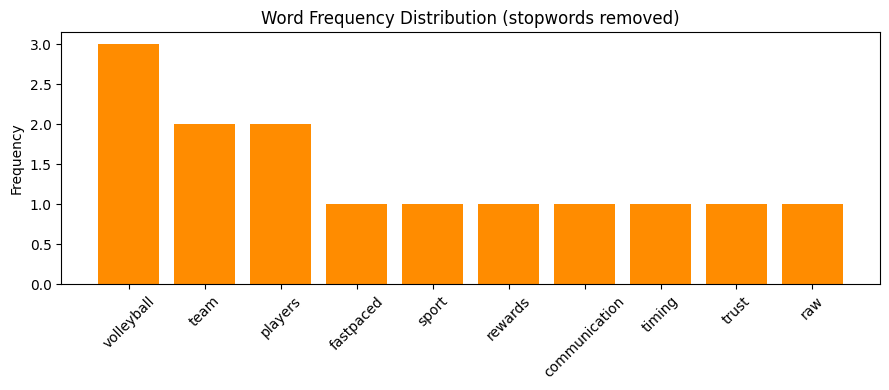

In [6]:
fdist = FreqDist(filtered_words)
for word, count in fdist.most_common(15):
    print(f"{word:<15}{count}")
top = fdist.most_common(10)
plt.figure(figsize=(9, 4))
plt.bar([w for w, c in top], [c for w, c in top], color="darkorange")
plt.xticks(rotation=45)
plt.ylabel("Frequency")
plt.title("Word Frequency Distribution (stopwords removed)")
plt.tight_layout()
plt.show()

Q2

In [7]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

alpha_words = re.findall(r"[A-Za-z]+", paragraph.lower())
print(len(alpha_words))
print(alpha_words)

123
['volleyball', 'is', 'a', 'fast', 'paced', 'team', 'sport', 'that', 'rewards', 'communication', 'timing', 'and', 'trust', 'more', 'than', 'raw', 'strength', 'six', 'players', 'on', 'each', 'side', 'of', 'the', 'net', 'work', 'together', 'to', 'pass', 'set', 'and', 'spike', 'the', 'ball', 'before', 'it', 'touches', 'the', 'floor', 'i', 'love', 'how', 'a', 'single', 'rally', 'can', 'swing', 'from', 'a', 'desperate', 'dive', 'to', 'a', 'perfectly', 'placed', 'attack', 'in', 'just', 'a', 'few', 'seconds', 'libero', 'players', 'don', 't', 'score', 'much', 'but', 'their', 'defensive', 'digs', 'keep', 'the', 'team', 'alive', 'and', 'the', 'crowd', 'roaring', 'playing', 'beach', 'volleyball', 'in', 'the', 'summer', 'with', 'sand', 'under', 'my', 'feet', 'and', 'only', 'one', 'partner', 'taught', 'me', 'how', 'important', 'teamwork', 'really', 'is', 'whether', 'it', 's', 'a', 'school', 'tournament', 'or', 'the', 'olympics', 'volleyball', 'always', 'makes', 'me', 'feel', 'energized', 'and', 

In [8]:
stop_words = set(stopwords.words("english"))
no_stop = [w for w in alpha_words if w not in stop_words]
print(len(no_stop))
print(no_stop)

68
['volleyball', 'fast', 'paced', 'team', 'sport', 'rewards', 'communication', 'timing', 'trust', 'raw', 'strength', 'six', 'players', 'side', 'net', 'work', 'together', 'pass', 'set', 'spike', 'ball', 'touches', 'floor', 'love', 'single', 'rally', 'swing', 'desperate', 'dive', 'perfectly', 'placed', 'attack', 'seconds', 'libero', 'players', 'score', 'much', 'defensive', 'digs', 'keep', 'team', 'alive', 'crowd', 'roaring', 'playing', 'beach', 'volleyball', 'summer', 'sand', 'feet', 'one', 'partner', 'taught', 'important', 'teamwork', 'really', 'whether', 'school', 'tournament', 'olympics', 'volleyball', 'always', 'makes', 'feel', 'energized', 'connected', 'everyone', 'court']


In [9]:
stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in no_stop]
print(stemmed)

['volleybal', 'fast', 'pace', 'team', 'sport', 'reward', 'commun', 'time', 'trust', 'raw', 'strength', 'six', 'player', 'side', 'net', 'work', 'togeth', 'pass', 'set', 'spike', 'ball', 'touch', 'floor', 'love', 'singl', 'ralli', 'swing', 'desper', 'dive', 'perfectli', 'place', 'attack', 'second', 'libero', 'player', 'score', 'much', 'defens', 'dig', 'keep', 'team', 'aliv', 'crowd', 'roar', 'play', 'beach', 'volleybal', 'summer', 'sand', 'feet', 'one', 'partner', 'taught', 'import', 'teamwork', 'realli', 'whether', 'school', 'tournament', 'olymp', 'volleybal', 'alway', 'make', 'feel', 'energ', 'connect', 'everyon', 'court']


In [10]:
lemmatizer = WordNetLemmatizer()

def wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("R"):
        return "r"
    return "n"

tagged = nltk.pos_tag(no_stop)
lemmatized = [w if t in ("NN", "NNP") else lemmatizer.lemmatize(w, wordnet_pos(t)) for w, t in tagged]
print(lemmatized)

['volleyball', 'fast', 'pace', 'team', 'sport', 'reward', 'communication', 'time', 'trust', 'raw', 'strength', 'six', 'player', 'side', 'net', 'work', 'together', 'pass', 'set', 'spike', 'ball', 'touch', 'floor', 'love', 'single', 'rally', 'swing', 'desperate', 'dive', 'perfectly', 'place', 'attack', 'second', 'libero', 'player', 'score', 'much', 'defensive', 'dig', 'keep', 'team', 'alive', 'crowd', 'roar', 'play', 'beach', 'volleyball', 'summer', 'sand', 'foot', 'one', 'partner', 'teach', 'important', 'teamwork', 'really', 'whether', 'school', 'tournament', 'olympics', 'volleyball', 'always', 'make', 'feel', 'energized', 'connect', 'everyone', 'court']


In [11]:
print(f"{'original':<14}{'stemmed':<14}{'lemmatized':<14}")
print("-" * 42)
for o, s, l in zip(no_stop, stemmed, lemmatized):
    if o != s or o != l:
        print(f"{o:<14}{s:<14}{l:<14}")
print()
print("unique originals  :", len(set(no_stop)))
print("unique stems      :", len(set(stemmed)))
print("unique lemmas     :", len(set(lemmatized)))
print()
print("Stemming chops suffixes with fixed rules, so it is fast but can produce non-words (e.g. 'perfectli', 'energ').")
print("Lemmatization uses a dictionary and part of speech, so it returns real words (e.g. 'players' -> 'player', 'playing' -> 'play') but is slower.")
print("Prefer stemming for search engines, indexing and large-scale text classification where speed and grouping related words matter.")
print("Prefer lemmatization for chatbots, sentiment analysis, text generation and anywhere readable, meaningful words matter.")

original      stemmed       lemmatized    
------------------------------------------
volleyball    volleybal     volleyball    
paced         pace          pace          
rewards       reward        reward        
communication commun        communication 
timing        time          time          
players       player        player        
together      togeth        together      
touches       touch         touch         
single        singl         single        
rally         ralli         rally         
desperate     desper        desperate     
perfectly     perfectli     perfectly     
placed        place         place         
seconds       second        second        
players       player        player        
defensive     defens        defensive     
digs          dig           dig           
alive         aliv          alive         
roaring       roar          roar          
playing       play          play          
volleyball    volleybal     volleyball    
feet       

Q3

In [12]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "The setter delivered a perfect set and the spiker hit a powerful spike to win the match.",
    "This new volleyball has a soft touch, great grip and stays stable during long beach games.",
    "Ticket prices for the national volleyball league final are high but the stadium atmosphere was amazing."
]
for i, t in enumerate(texts, 1):
    print(f"Text {i}: {t}")

Text 1: The setter delivered a perfect set and the spiker hit a powerful spike to win the match.
Text 2: This new volleyball has a soft touch, great grip and stays stable during long beach games.
Text 3: Ticket prices for the national volleyball league final are high but the stadium atmosphere was amazing.


In [13]:
cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print(bow_df)

        amazing  atmosphere  beach  delivered  final  games  great  grip  high  hit  league  long  match  national  new  perfect  powerful  prices  set  setter  soft  spike  spiker  stable  stadium  stays  ticket  touch  volleyball  win
Text 1        0           0      0          1      0      0      0     0     0    1       0     0      1         0    0        1         1       0    1       1     0      1       1       0        0      0       0      0           0    1
Text 2        0           0      1          0      0      1      1     1     0    0       0     1      0         0    1        0         0       0    0       0     1      0       0       1        0      1       0      1           1    0
Text 3        1           1      0          0      1      0      0     0     1    0       1     0      0         1    0        0         0       1    0       0     0      0       0       0        1      0       1      0           1    0


In [14]:
tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])
print(tfidf_df.round(3))

        amazing  atmosphere  beach  delivered  final  games  great   grip   high    hit  league   long  match  national    new  perfect  powerful  prices    set  setter   soft  spike  spiker  stable  stadium  stays  ticket  touch  volleyball    win
Text 1    0.000       0.000  0.000      0.316  0.000  0.000  0.000  0.000  0.000  0.316   0.000  0.000  0.316     0.000  0.000    0.316     0.316   0.000  0.316   0.316  0.000  0.316   0.316   0.000    0.000  0.000   0.000  0.000       0.000  0.316
Text 2    0.000       0.000  0.307      0.000  0.000  0.307  0.307  0.307  0.000  0.000   0.000  0.307  0.000     0.000  0.307    0.000     0.000   0.000  0.000   0.000  0.307  0.000   0.000   0.307    0.000  0.307   0.000  0.307       0.234  0.000
Text 3    0.323       0.323  0.000      0.000  0.323  0.000  0.000  0.000  0.323  0.000   0.323  0.000  0.000     0.323  0.000    0.000     0.000   0.323  0.000   0.000  0.000  0.000   0.000   0.000    0.323  0.000   0.323  0.000       0.246  0.000


In [15]:
for name, row in tfidf_df.iterrows():
    top3 = row.sort_values(ascending=False).head(3)
    print(name)
    for word, score in top3.items():
        print(f"   {word:<12}{score:.3f}")
    print(f"   -> '{', '.join(top3.index)}' have the highest TF-IDF in {name} because they appear in it often but rarely or never in the other texts, so they best describe its topic.")
    print()

Text 1
   delivered   0.316
   hit         0.316
   match       0.316
   -> 'delivered, hit, match' have the highest TF-IDF in Text 1 because they appear in it often but rarely or never in the other texts, so they best describe its topic.

Text 2
   games       0.307
   beach       0.307
   grip        0.307
   -> 'games, beach, grip' have the highest TF-IDF in Text 2 because they appear in it often but rarely or never in the other texts, so they best describe its topic.

Text 3
   amazing     0.323
   atmosphere  0.323
   final       0.323
   -> 'amazing, atmosphere, final' have the highest TF-IDF in Text 3 because they appear in it often but rarely or never in the other texts, so they best describe its topic.



Q4

In [16]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_a = ("The video challenge system uses several high speed cameras around the court to track the ball. "
          "When a coach disagrees with a referee decision, the system replays the rally in slow motion. "
          "It shows whether the ball was in or out and whether a player touched the net. "
          "This technology makes volleyball matches fairer and reduces arguments on the court.")
text_b = ("Wearable sensors are small devices attached to the wrist or waist of a player during training. "
          "They measure jump height, arm swing speed and the number of spikes on the court in every practice. "
          "Coaches use this data to track the workload of each player and prevent injuries. "
          "This technology helps volleyball players improve their performance with every ball they hit.")
print(text_a)
print()
print(text_b)

The video challenge system uses several high speed cameras around the court to track the ball. When a coach disagrees with a referee decision, the system replays the rally in slow motion. It shows whether the ball was in or out and whether a player touched the net. This technology makes volleyball matches fairer and reduces arguments on the court.

Wearable sensors are small devices attached to the wrist or waist of a player during training. They measure jump height, arm swing speed and the number of spikes on the court in every practice. Coaches use this data to track the workload of each player and prevent injuries. This technology helps volleyball players improve their performance with every ball they hit.


In [17]:
stop_words = set(stopwords.words("english"))

def preprocess(text):
    text = re.sub(r"[^\w\s]", "", text.lower())
    tokens = word_tokenize(text)
    return [t for t in tokens if t not in stop_words]

tokens_a = preprocess(text_a)
tokens_b = preprocess(text_b)
print(tokens_a)
print()
print(tokens_b)

['video', 'challenge', 'system', 'uses', 'several', 'high', 'speed', 'cameras', 'around', 'court', 'track', 'ball', 'coach', 'disagrees', 'referee', 'decision', 'system', 'replays', 'rally', 'slow', 'motion', 'shows', 'whether', 'ball', 'whether', 'player', 'touched', 'net', 'technology', 'makes', 'volleyball', 'matches', 'fairer', 'reduces', 'arguments', 'court']

['wearable', 'sensors', 'small', 'devices', 'attached', 'wrist', 'waist', 'player', 'training', 'measure', 'jump', 'height', 'arm', 'swing', 'speed', 'number', 'spikes', 'court', 'every', 'practice', 'coaches', 'use', 'data', 'track', 'workload', 'player', 'prevent', 'injuries', 'technology', 'helps', 'volleyball', 'players', 'improve', 'performance', 'every', 'ball', 'hit']


In [18]:
set_a, set_b = set(tokens_a), set(tokens_b)
common = set_a & set_b
union = set_a | set_b
jaccard = len(common) / len(union)
print("common words:", sorted(common))
print("intersection:", len(common), " union:", len(union))
print("Jaccard similarity:", round(jaccard, 4))

common words: ['ball', 'court', 'player', 'speed', 'technology', 'track', 'volleyball']
intersection: 7  union: 60
Jaccard similarity: 0.1167


In [19]:
docs = [" ".join(tokens_a), " ".join(tokens_b)]
tfidf_vec = TfidfVectorizer()
tfidf_vecs = tfidf_vec.fit_transform(docs)
cosine = cosine_similarity(tfidf_vecs[0], tfidf_vecs[1])[0][0]
print("Cosine similarity:", round(cosine, 4))

Cosine similarity: 0.1375


In [20]:
print(f"Jaccard similarity : {jaccard:.4f}")
print(f"Cosine similarity  : {cosine:.4f}")
print()
print("Jaccard only checks which unique words are shared and ignores how often a word occurs or how important it is.")
print("Cosine similarity with TF-IDF weights words by frequency and rarity, so shared generic words count less than shared topic words.")
print("The only shared words are", sorted(common), "- mostly generic words, so both scores are low and correctly show the texts describe different technologies.")
print("For this case cosine similarity with TF-IDF gives better insight because it is not distorted by common words and also works well when the texts differ in length.")

Jaccard similarity : 0.1167
Cosine similarity  : 0.1375

Jaccard only checks which unique words are shared and ignores how often a word occurs or how important it is.
Cosine similarity with TF-IDF weights words by frequency and rarity, so shared generic words count less than shared topic words.
The only shared words are ['ball', 'court', 'player', 'speed', 'technology', 'track', 'volleyball'] - mostly generic words, so both scores are low and correctly show the texts describe different technologies.
For this case cosine similarity with TF-IDF gives better insight because it is not distorted by common words and also works well when the texts differ in length.


Q5

In [21]:
import pandas as pd
from textblob import TextBlob

reviews = [
    "This volleyball is excellent. The grip is amazing and it feels great to serve and spike.",
    "I love this net system, it is sturdy, easy to set up and perfect for our beach games.",
    "Terrible quality. The ball lost its shape after two games and the stitching is bad.",
    "The knee pads are awful, uncomfortable and they slip down every time I dive.",
    "The volleyball shoes arrived on Monday in a standard box.",
    "I bought the ball for my club, it is size five and white.",
    "Fantastic coaching service! The trainers are friendly, helpful and my passing improved a lot.",
    "Worst experience ever, the court booking was cancelled and nobody apologised.",
    "The jersey is beautiful and comfortable, I am very happy with my purchase."
]
rows = []
for r in reviews:
    sentiment = TextBlob(r).sentiment
    rows.append({"review": r, "polarity": round(sentiment.polarity, 3), "subjectivity": round(sentiment.subjectivity, 3)})
df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 250)
print(df)

                                                                                      review  polarity  subjectivity
0   This volleyball is excellent. The grip is amazing and it feels great to serve and spike.     0.800         0.883
1      I love this net system, it is sturdy, easy to set up and perfect for our beach games.     0.483         0.608
2        Terrible quality. The ball lost its shape after two games and the stitching is bad.    -0.850         0.833
3               The knee pads are awful, uncomfortable and they slip down every time I dive.    -0.552         0.763
4                                  The volleyball shoes arrived on Monday in a standard box.     0.000         0.000
5                                  I bought the ball for my club, it is size five and white.     0.000         0.000
6  Fantastic coaching service! The trainers are friendly, helpful and my passing improved...     0.438         0.700
7              Worst experience ever, the court booking was canc

In [22]:
def classify(p):
    if p > 0.1:
        return "Positive"
    elif p < -0.1:
        return "Negative"
    return "Neutral"

df["sentiment"] = df["polarity"].apply(classify)
print(df[["review", "polarity", "sentiment"]])
print()
print(df["sentiment"].value_counts())

                                                                                      review  polarity sentiment
0   This volleyball is excellent. The grip is amazing and it feels great to serve and spike.     0.800  Positive
1      I love this net system, it is sturdy, easy to set up and perfect for our beach games.     0.483  Positive
2        Terrible quality. The ball lost its shape after two games and the stitching is bad.    -0.850  Negative
3               The knee pads are awful, uncomfortable and they slip down every time I dive.    -0.552  Negative
4                                  The volleyball shoes arrived on Monday in a standard box.     0.000   Neutral
5                                  I bought the ball for my club, it is size five and white.     0.000   Neutral
6  Fantastic coaching service! The trainers are friendly, helpful and my passing improved...     0.438  Positive
7              Worst experience ever, the court booking was cancelled and nobody apologised.    

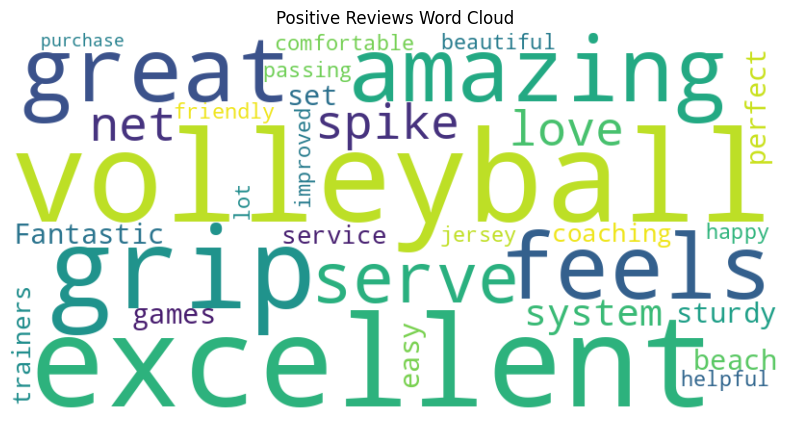

In [23]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

positive_text = " ".join(df[df["sentiment"] == "Positive"]["review"])
wc = WordCloud(width=800, height=400, background_color="white", colormap="viridis").generate(positive_text)
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Positive Reviews Word Cloud")
plt.show()

Q6

In [24]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

np.random.seed(42)
tf.random.set_seed(42)

training_text = ("volleyball is a team sport where two teams play on a court divided by a net. "
                 "each team tries to send the ball over the net and make it touch the ground on the other side. "
                 "players pass the ball to a setter and the setter lifts it for a strong spike. "
                 "good communication and quick movement help a team win every rally. "
                 "volleyball teaches players to trust each other and to stay calm under pressure. "
                 "a great team always celebrates every point together and learns from every mistake. "
                 "playing volleyball on the beach in the summer is fun and keeps everyone active and happy.")
print(len(training_text.split()), "words")
print(training_text)

105 words
volleyball is a team sport where two teams play on a court divided by a net. each team tries to send the ball over the net and make it touch the ground on the other side. players pass the ball to a setter and the setter lifts it for a strong spike. good communication and quick movement help a team win every rally. volleyball teaches players to trust each other and to stay calm under pressure. a great team always celebrates every point together and learns from every mistake. playing volleyball on the beach in the summer is fun and keeps everyone active and happy.


In [25]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
vocab_size = len(tokenizer.word_index) + 1
print("vocabulary size:", vocab_size)
print(dict(list(tokenizer.word_index.items())[:15]))

vocabulary size: 67
{'the': 1, 'a': 2, 'and': 3, 'team': 4, 'to': 5, 'volleyball': 6, 'on': 7, 'every': 8, 'is': 9, 'net': 10, 'each': 11, 'ball': 12, 'it': 13, 'other': 14, 'players': 15}


In [26]:
input_sequences = []
for line in training_text.split(". "):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[: i + 1])

max_len = max(len(s) for s in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding="pre")
X = input_sequences[:, :-1]
y = input_sequences[:, -1]
print("total sequences:", len(input_sequences))
print("X shape:", X.shape, " y shape:", y.shape)
print(X[:3])
print(y[:3])

total sequences: 98
X shape: (98, 19)  y shape: (98,)
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 6]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 6 9]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 6 9 2]]
[9 2 4]


In [27]:
model = Sequential([
    Embedding(vocab_size, 32),
    LSTM(64),
    Dense(vocab_size, activation="softmax")
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, max_len - 1))
for layer in model.layers:
    print(layer.name, layer.count_params())
print("total parameters:", model.count_params())

embedding 2144
lstm 24832
dense 4355
total parameters: 31331


In [28]:
history = model.fit(X, y, epochs=250, verbose=0)
print("final loss    :", round(history.history["loss"][-1], 4))
print("final accuracy:", round(history.history["accuracy"][-1], 4))

final loss    : 0.2426
final accuracy: 0.9898


In [29]:
def generate_text(seed, n_words=8, temperature=0.8):
    result = seed
    for _ in range(n_words):
        seq = tokenizer.texts_to_sequences([result])[0]
        seq = pad_sequences([seq], maxlen=max_len - 1, padding="pre")
        probs = model.predict(seq, verbose=0)[0].astype("float64")
        probs = np.log(probs + 1e-9) / temperature
        probs = np.exp(probs) / np.sum(np.exp(probs))
        pred = np.random.choice(len(probs), p=probs)
        result += " " + tokenizer.index_word.get(pred, "")
    return result

for _ in range(3):
    print(generate_text("volleyball"))

volleyball is on a team sport where two play


volleyball pass to the beach in the setter the


volleyball is a team sport where two teams play
